<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Victor/UNIDAD2RegresionLog_23111511.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Curso: modelos de aprendizaje**

**UNIDAD 2**


---

* **NOMBRE:** Victor Manuel Landeros Ramirez
* **NO. CONTROL:** 23111511

In [ ]:
# En Colab puedes subir data.csv a la sesión; en Jupyter local colócalo junto al notebook.
# No se necesita montar Google Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [44]:
import os
DIR = "/content/drive/MyDrive/Colab Notebooks"
os.chdir(DIR)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---
## **<font color="#895cf9">Explica brevemente el uso de las librerías del segmento anterior</font>**

- **pandas / numpy:** permiten manipular tablas y realizar cálculos numéricos.
- **matplotlib / seaborn:** sirven para representar gráficamente distribuciones, frecuencias y correlaciones.
- **SimpleImputer:** completa valores faltantes cuando existen.
- **StandardScaler / MinMaxScaler:** ajustan las escalas de las variables numéricas.
- **OneHotEncoder / OrdinalEncoder:** transforman categorías a números cuando se requiere.
- **FunctionTransformer:** aplica operaciones matemáticas personalizadas a columnas.
- **ColumnTransformer / Pipeline:** integran las transformaciones y el estimador en un proceso reproducible.
- **LogisticRegression:** aprende a distinguir las dos clases de diagnóstico.
- **Métricas de clasificación:** matriz de confusión, precisión, sensibilidad y exactitud evalúan las predicciones.
- **PCA / PolynomialFeatures / LinearRegression:** herramientas adicionales importadas, aunque no son necesarias en el modelo final de esta práctica.


In [ ]:
data_df = pd.read_csv('data.csv')
print('Dimensiones:', data_df.shape)
data_df.head()

Dimensiones: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [ ]:
# El identificador representa a cada observación
if 'id' in data_df.columns:
    data_df.set_index('id', inplace=True)

# Eliminar columnas que no contienen información
columnas_vacias = data_df.columns[data_df.isna().all()]
data_df.drop(columns=columnas_vacias, inplace=True)

print('Filas y columnas:', data_df.shape)

Filas y columnas: (569, 31)


In [ ]:
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820




1a) Estadísticas descriptivas para todas las variables del dataframe.

In [ ]:
# Resumen de tendencia central y dispersión de variables numéricas.
data_df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [ ]:
# Resumen de la variable de diagnóstico.
data_df.describe(include='object')

,diagnosis
count,569
unique,2
top,B
freq,357


1b) Valores únicos por variable para identificar posibles variables categóricas.

In [ ]:
num_cols = data_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist()
print('Numéricas:',len(num_cols),'| Categóricas:',cat_cols)
data_df.nunique().sort_values()

Numéricas: 30 | Categóricas: ['diagnosis']


,0
diagnosis,2
smoothness_worst,411
symmetry_mean,432
radius_mean,456
radius_worst,457
smoothness_mean,474
texture_mean,479
concave points_worst,492
symmetry_se,498
fractal_dimension_mean,499


In [ ]:
for col in cat_cols:
    print(f'Categorías en {col}:')
    print(data_df[col].value_counts())

Categorías en diagnosis:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [ ]:
# Comprobación de valores únicos en algunas columnas numéricas.
data_df[num_cols].nunique().sort_values().head(10)

,0
smoothness_worst,411
symmetry_mean,432
radius_mean,456
radius_worst,457
smoothness_mean,474
texture_mean,479
concave points_worst,492
symmetry_se,498
fractal_dimension_mean,499
symmetry_worst,500


1c) Búsqueda de valores faltantes.

In [ ]:
# Para cada columna, se calcula el total de celdas vacías y su porcentaje.
missing = data_df.isna().sum()
missing_pct = 100 * missing / len(data_df)
print('Número total de valores faltantes:', int(missing.sum()))
pd.DataFrame({'faltantes': missing, 'porcentaje': missing_pct}).query('faltantes > 0')

Número total de valores faltantes: 0


,faltantes,porcentaje


1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

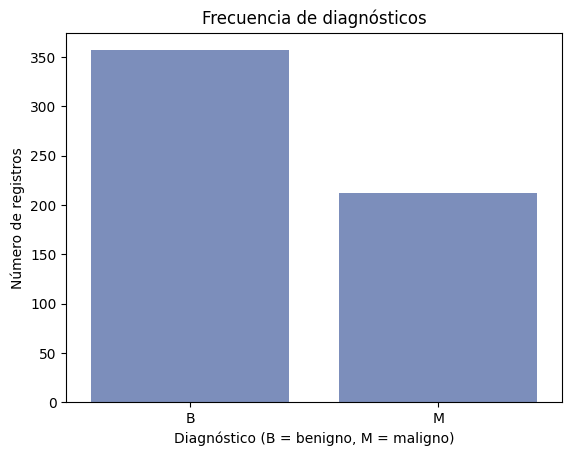

diagnosis
B    357
M    212
Name: count, dtype: int64


In [ ]:
sns.countplot(data=data_df, x='diagnosis', order=['B','M'], color='#7189c5')
plt.title('Frecuencia de diagnósticos')
plt.xlabel('Diagnóstico (B = benigno, M = maligno)')
plt.ylabel('Número de registros')
plt.show()
print(data_df['diagnosis'].value_counts())

2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

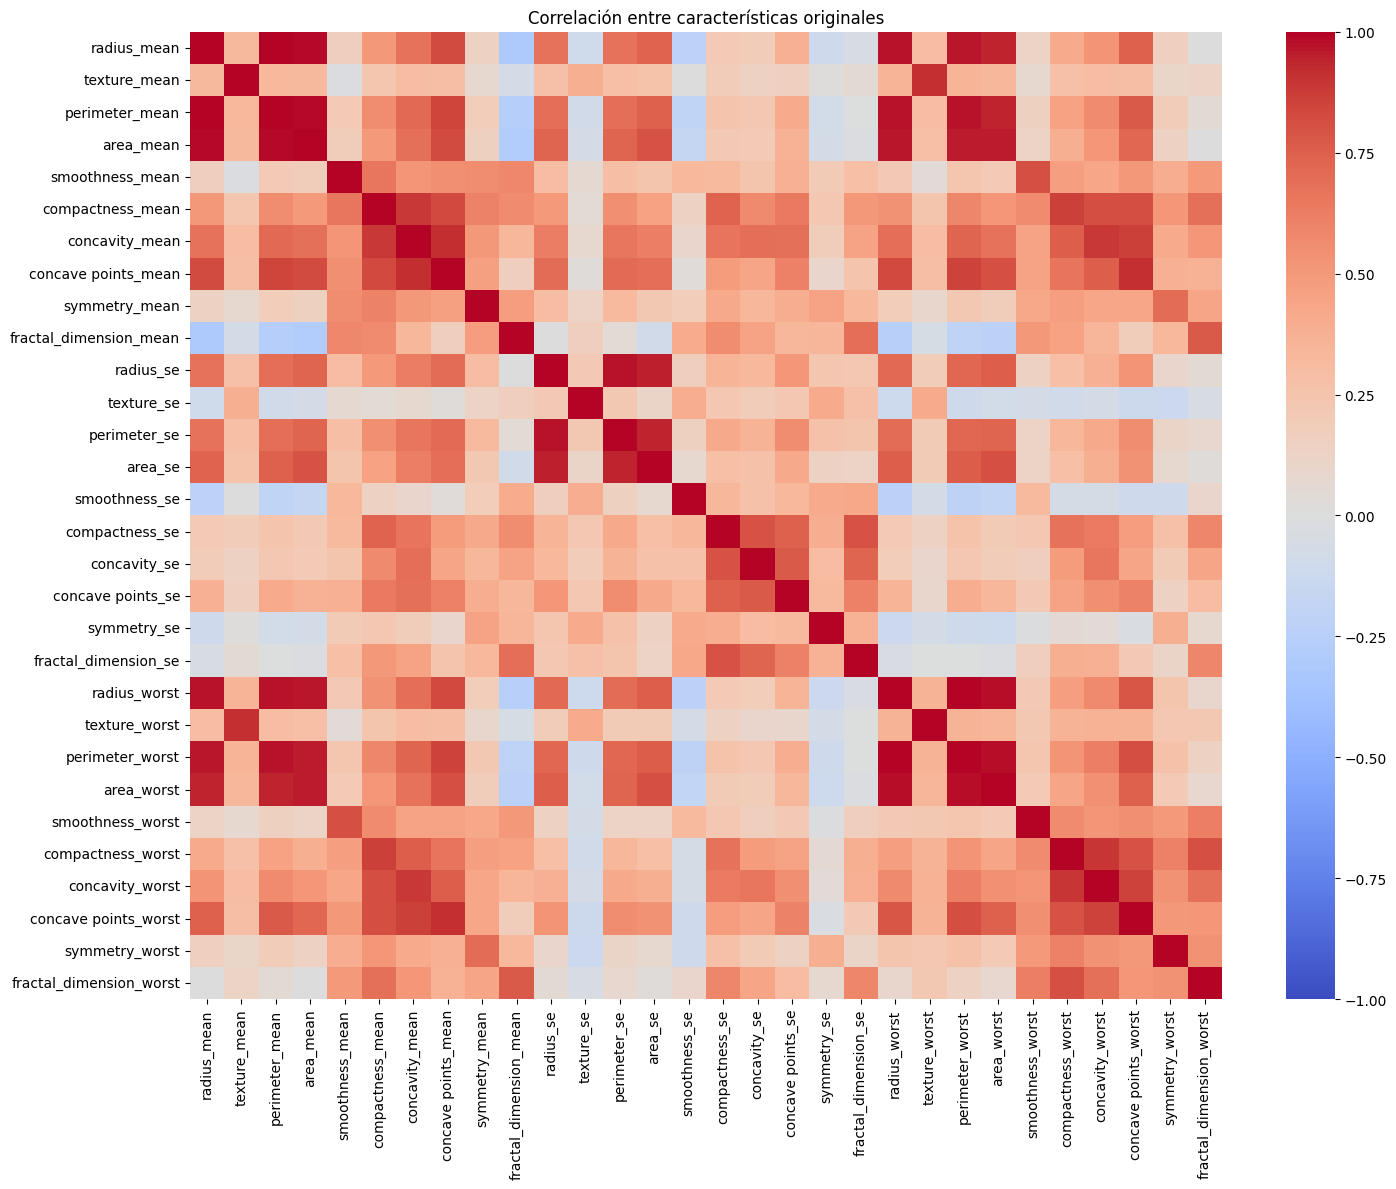

In [ ]:
numeric_df = data_df.select_dtypes(include=np.number)
plt.figure(figsize=(15,12))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlación entre características originales')
plt.tight_layout()
plt.show()

Si te fijas en los valores de correlación entre las variables `_mean` y `_worst`, se observa multicolinealidad: varias mediciones aportan información muy parecida. Para reducirla, se eliminan las columnas `_worst` y se revisan las correlaciones restantes.

**Observación:** la eliminación de variables se usa aquí como ejercicio de análisis; en un proyecto real convendría seleccionar las características usando únicamente los datos de entrenamiento.

# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [ ]:
# Primero se eliminan todas las mediciones de tipo 'worst'.
worst_cols = [c for c in data_df.columns if c.endswith('_worst')]
new_data_df = data_df.drop(columns=worst_cols).copy()
print('Columnas worst eliminadas:',len(worst_cols))
print('Dimensiones actuales:',new_data_df.shape)
new_data_df.head()

Columnas worst eliminadas: 10
Dimensiones actuales: (569, 21)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115


En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])



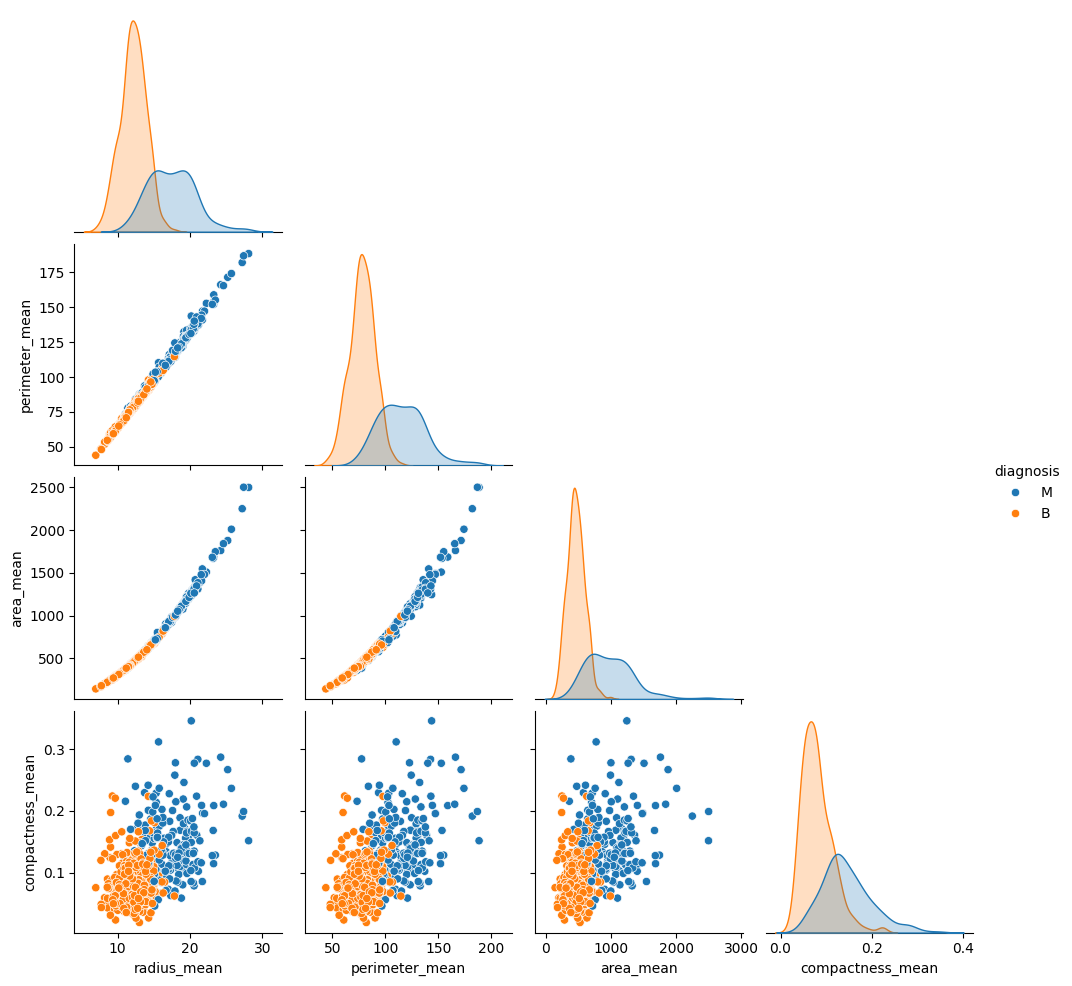

In [ ]:
# Relaciones entre variables de tamaño y compactación.
sns.pairplot(new_data_df, vars=['radius_mean','perimeter_mean','area_mean','compactness_mean'], hue='diagnosis', corner=True)
plt.show()

De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.


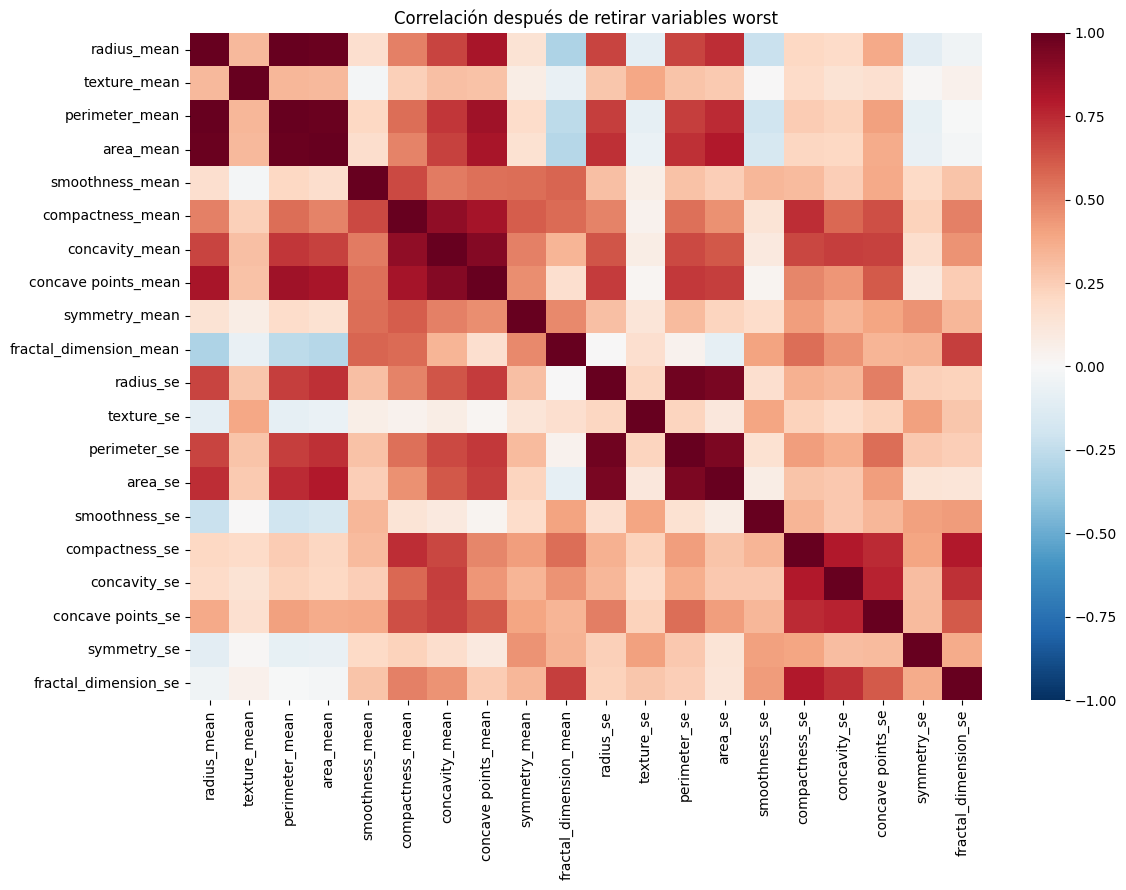

In [ ]:
numeric_df_nuevo = new_data_df.select_dtypes(include=np.number)
plt.figure(figsize=(12,9))
sns.heatmap(numeric_df_nuevo.corr(), cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlación después de retirar variables worst')
plt.tight_layout()
plt.show()

3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [ ]:
# Conservamos radius_mean y compactness_mean como representantes de sus grupos.
extra_cols = ['perimeter_mean','area_mean','concavity_mean','concave points_mean',
              'perimeter_se','area_se','concavity_se','concave points_se']
columnas_a_eliminar = worst_cols + extra_cols
new_data_df = data_df.drop(columns=columnas_a_eliminar).copy()
print('Características numéricas restantes:',new_data_df.select_dtypes(include=np.number).shape[1])
new_data_df.head()

Características numéricas restantes: 12


,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

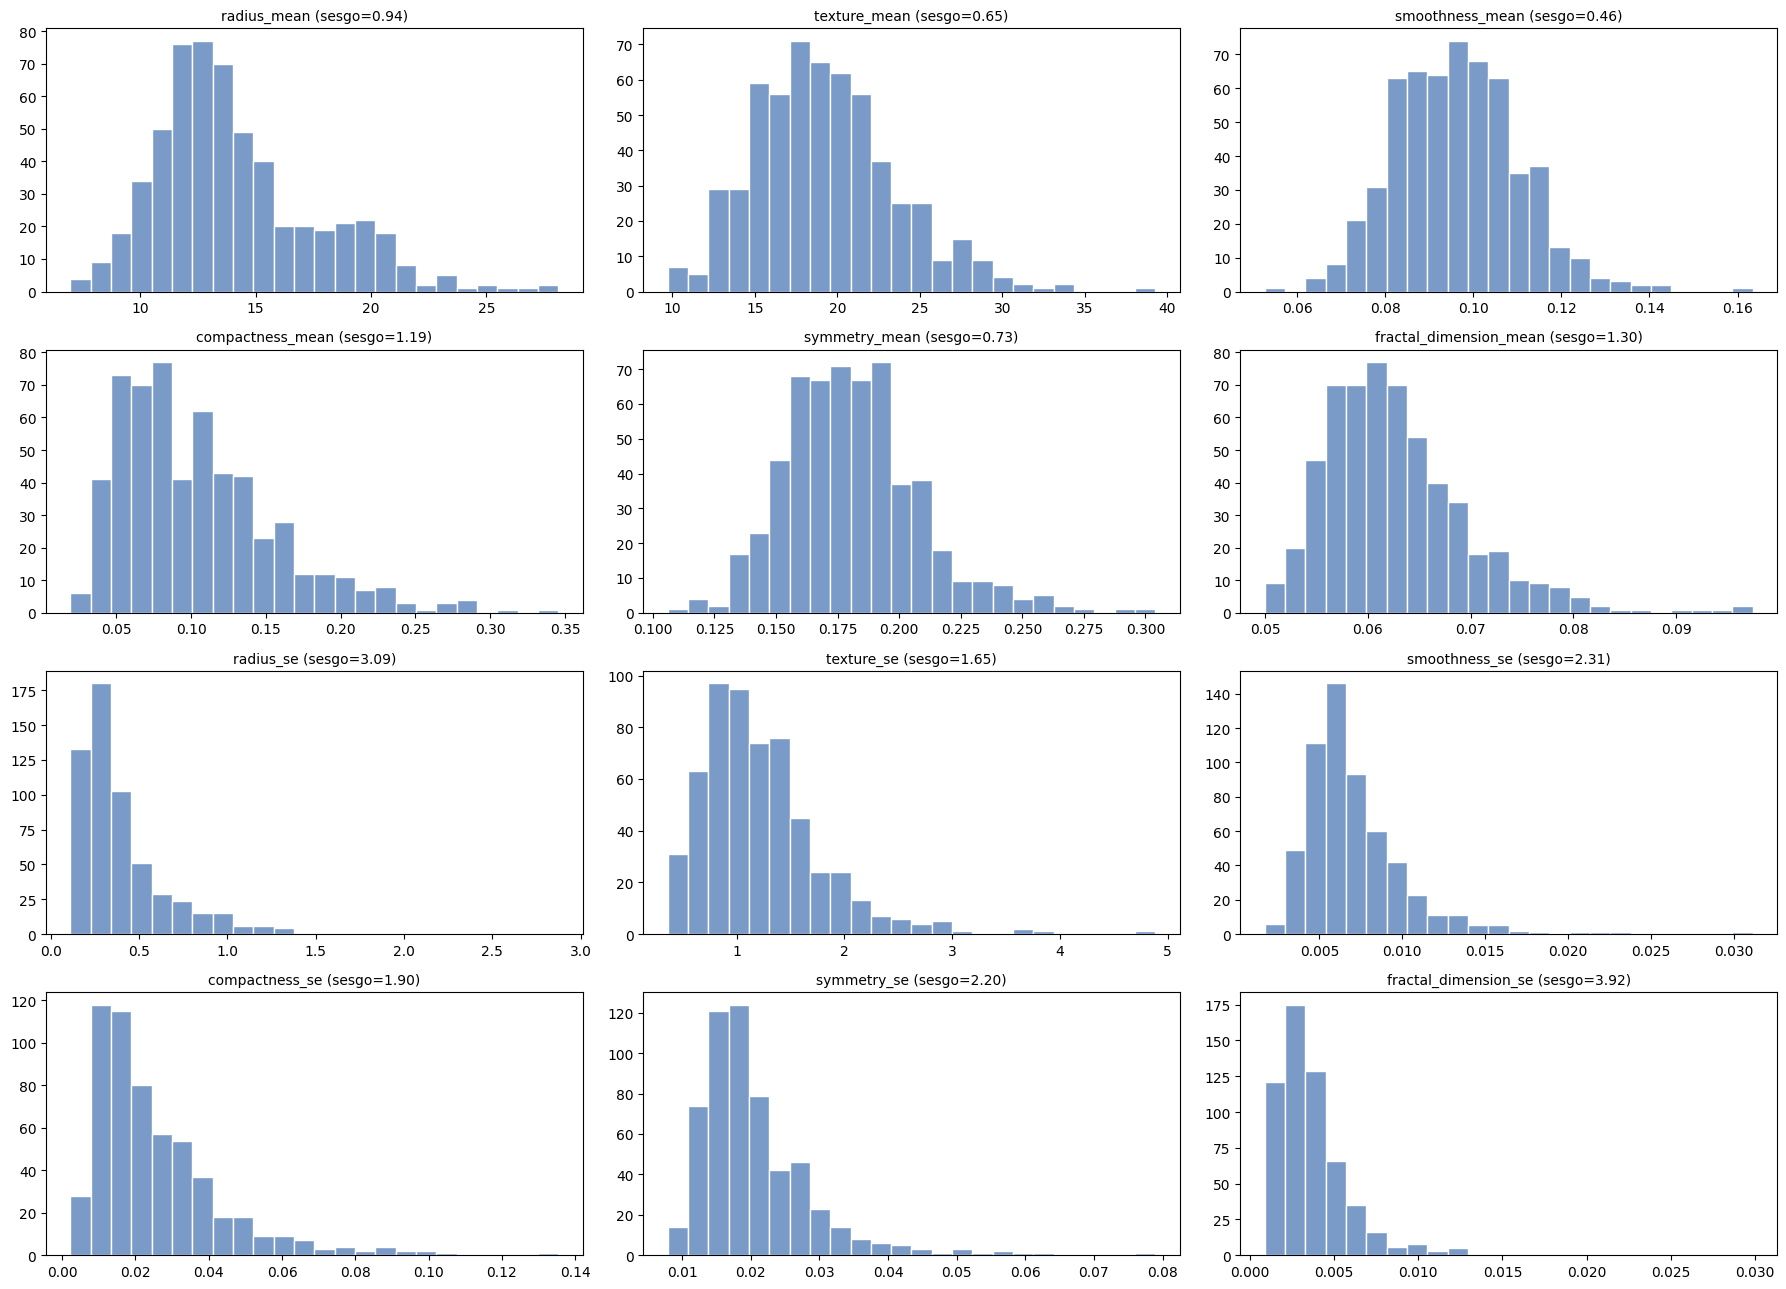

In [ ]:
# Los histogramas permiten observar asimetría; sesgo > 1 indica asimetría positiva notable.
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()
fig, axes = plt.subplots(4,3,figsize=(18,13))
skew_cols = []
for col,ax in zip(num_cols,axes.ravel()):
    ax.hist(new_data_df[col].dropna(),bins=24,color='#7a9ac8',edgecolor='white')
    ax.set_title(f'{col} (sesgo={new_data_df[col].skew():.2f})',fontsize=10)
    if new_data_df[col].skew()>1:
        skew_cols.append(col)
plt.tight_layout()
plt.show()

In [ ]:
print('Variables con asimetría positiva:',skew_cols)

Variables con asimetría positiva: ['compactness_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se', 'fractal_dimension_se']


4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]


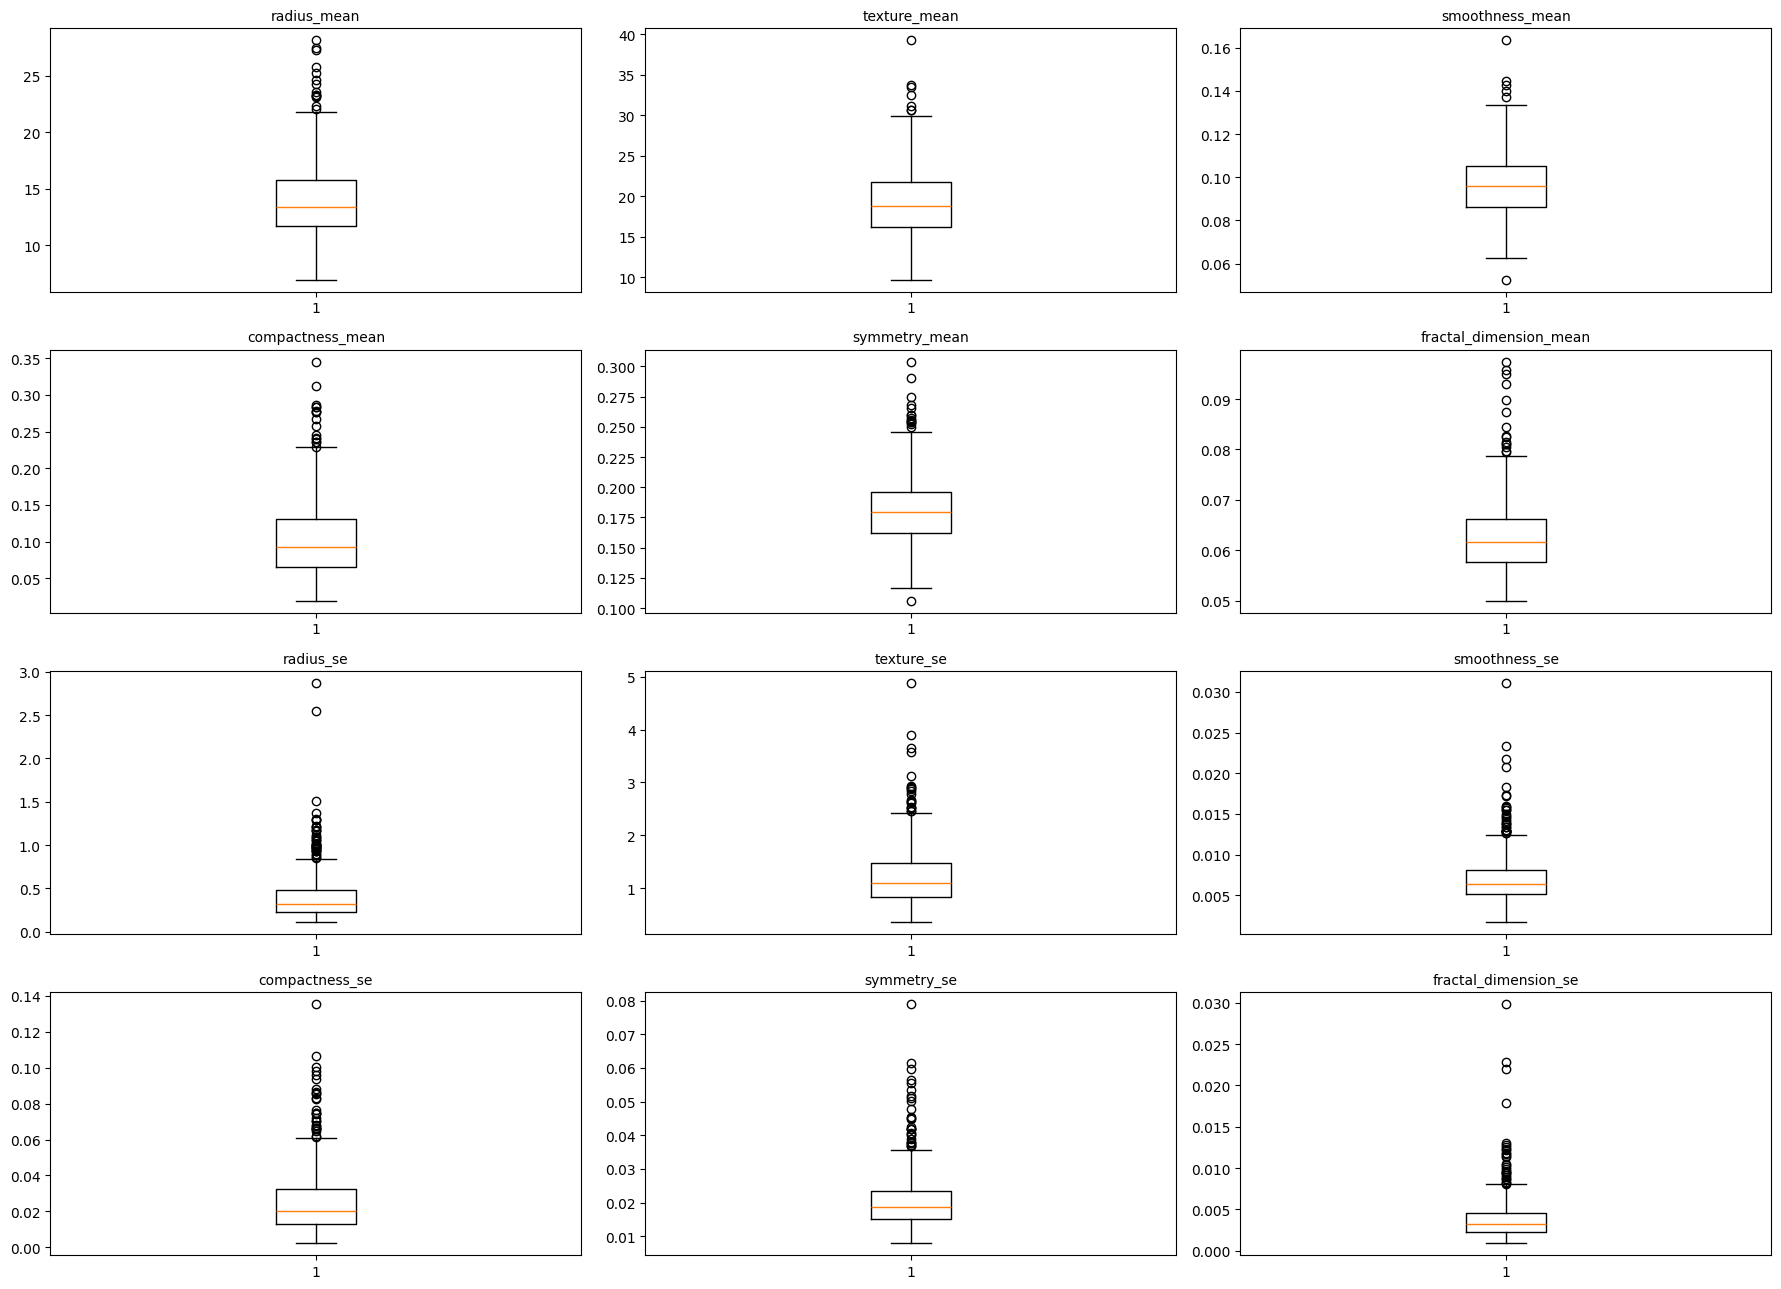

In [ ]:
# Los diagramas de caja permiten observar rangos y valores atípicos.
fig, axes = plt.subplots(4,3,figsize=(18,13))
for col,ax in zip(num_cols,axes.ravel()):
    ax.boxplot(new_data_df[col].dropna(),vert=True)
    ax.set_title(col,fontsize=10)
plt.tight_layout()
plt.show()
# Escalaremos las columnas que no estén en la lista de transformación por asimetría.
scale_cols = [col for col in num_cols if col not in skew_cols]

In [ ]:
print('Variables que se escalarán sin transformación de raíz:',scale_cols)

Variables que se escalarán sin transformación de raíz: ['radius_mean', 'texture_mean', 'smoothness_mean', 'symmetry_mean']


Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [ ]:
# Se vuelve a cargar el archivo para iniciar el entrenamiento desde datos originales.
data_df = pd.read_csv('data.csv').set_index('id')
data_df.drop(columns=data_df.columns[data_df.isna().all()],inplace=True)
print(data_df.shape)

(569, 31)


In [ ]:
X = data_df.drop(columns='diagnosis').copy()
y = data_df['diagnosis'].copy()
print('Entradas:',X.shape,'| Etiquetas:',y.value_counts().to_dict())

Entradas: (569, 30) | Etiquetas: {'B': 357, 'M': 212}


In [ ]:
from sklearn.model_selection import train_test_split
# Separación estratificada: se mantiene la proporción de clases en ambos conjuntos.
Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print('Entrenamiento:',len(Xtrain),'| Prueba:',len(Xtest))

Entrenamiento: 455 | Prueba: 114


5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [ ]:
# Primer modelo: se eliminan las 18 variables correlacionadas seleccionadas.
preprocessing = ColumnTransformer([('drop_correlacionadas','drop',columnas_a_eliminar)],remainder='passthrough')
print('Variables eliminadas:',len(columnas_a_eliminar))

Variables eliminadas: 18


5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [ ]:
# El pipeline asegura que el mismo preprocesamiento se aplique en entrenamiento y prueba.
logr_model = make_pipeline(preprocessing,LogisticRegression(max_iter=10000))
logr_model.fit(Xtrain,ytrain)
predictions = logr_model.predict(Xtest)
cm1 = confusion_matrix(ytest,predictions,labels=['B','M'])
print('Matriz de confusión (filas reales B,M; columnas predichas B,M):\n',cm1)
print('Recall M:',round(recall_score(ytest,predictions,pos_label='M'),4))
print('Precision M:',round(precision_score(ytest,predictions,pos_label='M'),4))
print('Accuracy:',round(accuracy_score(ytest,predictions),4))

Matriz de confusión (filas reales B,M; columnas predichas B,M):
 [[69  3]
 [12 30]]
Recall M: 0.7143
Precision M: 0.9091
Accuracy: 0.8684


<font color="ORANGE">**INTERPRETACIÓN DEL MODELO BASELINE**</font>

En la matriz (orden B, M), se identificaron **69 benignos correctos**, **3 benignos clasificados como malignos**, **12 malignos clasificados como benignos** y **30 malignos correctos**. La exactitud fue **86.84%**, la sensibilidad para malignos **71.43%** y la precisión para malignos **90.91%**. Es especialmente importante revisar los malignos no detectados (falsos negativos).

Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [ ]:
# Las columnas sesgadas reciben raíz cuadrada y escalado; las demás solo escalado.
# Los conjuntos son disjuntos para evitar repetir características en la matriz final.
preprocessing2 = ColumnTransformer([
    ('raiz_y_escala',make_pipeline(FunctionTransformer(np.sqrt),StandardScaler()),skew_cols),
    ('escala',StandardScaler(),scale_cols)
],remainder='drop')
print('Columnas transformadas:',len(skew_cols),'| Solo escaladas:',len(scale_cols))

Columnas transformadas: 8 | Solo escaladas: 4


6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [ ]:
logr_model2 = make_pipeline(preprocessing2,LogisticRegression(max_iter=10000))
logr_model2.fit(Xtrain,ytrain)
predictions2 = logr_model2.predict(Xtest)
cm2 = confusion_matrix(ytest,predictions2,labels=['B','M'])
print('Matriz de confusión (filas reales B,M; columnas predichas B,M):\n',cm2)
print('Recall M:',round(recall_score(ytest,predictions2,pos_label='M'),4))
print('Precision M:',round(precision_score(ytest,predictions2,pos_label='M'),4))
print('Accuracy:',round(accuracy_score(ytest,predictions2),4))

Matriz de confusión (filas reales B,M; columnas predichas B,M):
 [[68  4]
 [ 6 36]]
Recall M: 0.8571
Precision M: 0.9
Accuracy: 0.9123


<font color="ORANGE">**INTERPRETACIÓN DEL MODELO CON TRANSFORMACIONES**</font>

En la matriz (orden B, M), se identificaron **68 benignos correctos**, **4 benignos clasificados como malignos**, **6 malignos clasificados como benignos** y **36 malignos correctos**. La exactitud fue **91.23%**, la sensibilidad para malignos **85.71%** y la precisión para malignos **90.00%**. Es especialmente importante revisar los malignos no detectados (falsos negativos).

<font color="ORANGE">**CONCLUSIÓN DE LA PRÁCTICA**</font>

En esta práctica pude comprender mejor cómo funciona la regresión logística y la importancia de preparar correctamente los datos antes de entrenar un modelo. Al comparar los resultados, observé que el segundo modelo obtuvo una mejor exactitud y redujo los errores al identificar tumores malignos. También aprendí que no solo importa obtener un buen porcentaje de precisión, sino analizar otros resultados para saber qué tan confiable es el modelo.